In [15]:
import nmrglue as ng
import matplotlib.pyplot as plt
import zipfile
import tempfile
import os
import pyspecdata as psd
from itertools import cycle

In [16]:
def read_pdata_from_zip(zip_path, pdata_path):
    "Function to read pdata from zip file using temporary directory"
    with zipfile.ZipFile(zip_path, "r") as z:
        with tempfile.TemporaryDirectory() as temp_dir:
            # Extract the pdata directory to the temporary directory
            for file in z.namelist():
                if file.startswith(pdata_path):
                    z.extract(file, temp_dir)
            # Construct the full path to the extracted pdata directory
            extracted_pdata_path = os.path.join(temp_dir, pdata_path)
            # Read in the processed Bruker data
            dic, data = ng.bruker.read_pdata(extracted_pdata_path)
    return dic, data
def load_pdata_as_nddata(zipfile, pdata, exp_type):
    # Path to the ZIP file
    zip_path = psd.search_filename(zipfile, exp_type=exp_type, unique=True)
    # Define the path to the pdata within the zip
    pdata_path = f"{zipfile.replace('.zip','')}/{pdata[0]}/pdata/{pdata[1]}"
    # Read in the processed Bruker data from the zip file
    # Convert the data to a universal dictionary (udic) format
    # and create the NMR spectrum object with ppm axis
    dic, data = read_pdata_from_zip(zip_path, pdata_path)
    uc = ng.fileiobase.uc_from_udic(ng.bruker.guess_udic(dic, data))
    # Plot the spectrum
    retval = (
        psd.nddata(data.real, [-1], ["t2"])
        .setaxis("t2", uc.ppm_scale())
        .set_units("t2", "ppm")
        .set_prop("x_inverted", True)["t2", ::-1]
    )
    return retval    

In [17]:
display_range = (2.5,4.75)

# First make the baseline by combining the background and dataset

## Normalize the background

1: background |||ppm



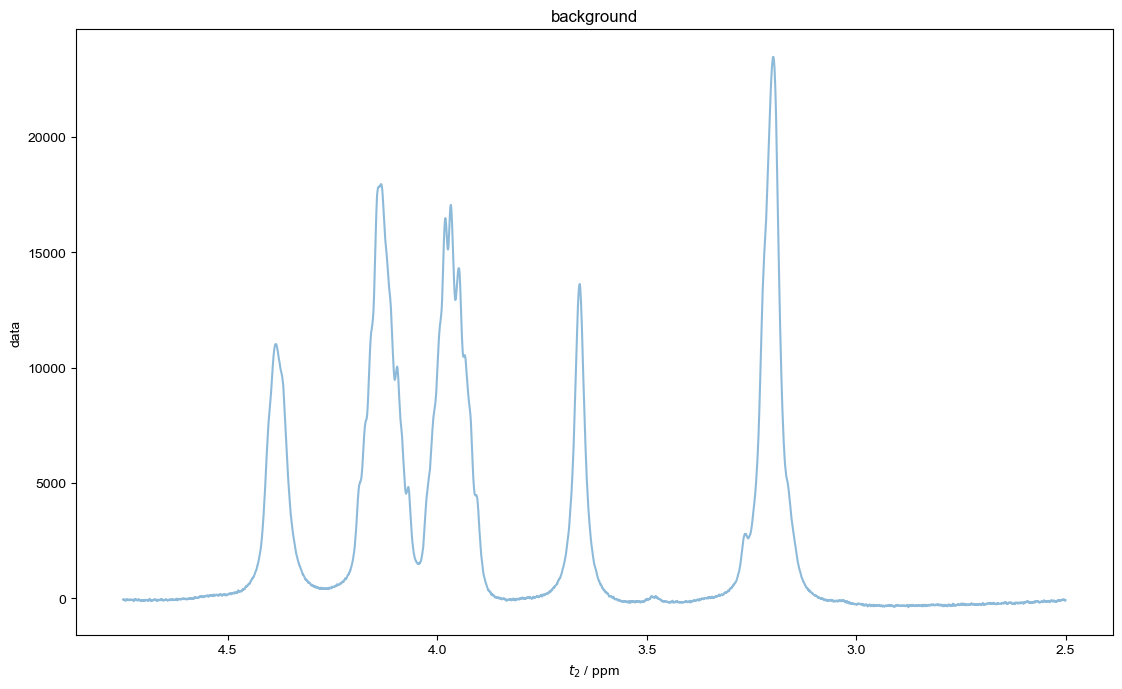

In [37]:
baseline_for_int = load_pdata_as_nddata("Background.zip", (1,1), "NMR_data_RS")
baseline_for_int = baseline_for_int["t2":display_range]
with psd.figlist_var() as fl:
    fl.next("background")
    fl.plot(baseline_for_int)

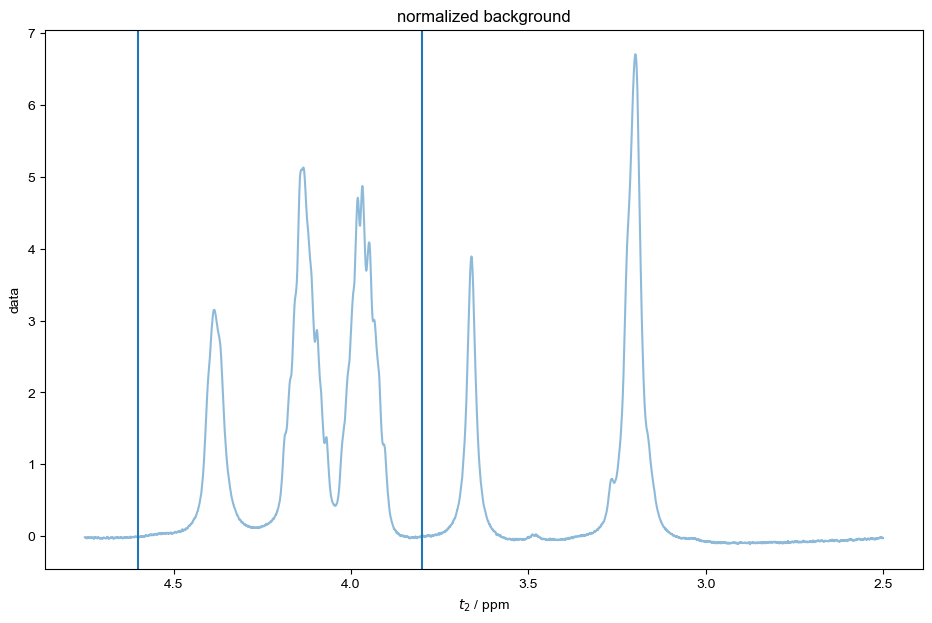

In [38]:
aot_range = (3.8,4.6)
integral = baseline_for_int["t2":aot_range].integrate("t2")
baseline_for_int /= integral.item()
fl.next("normalized background")
fl.plot(baseline_for_int)
plt.axvline(aot_range[0])
plt.axvline(aot_range[1])

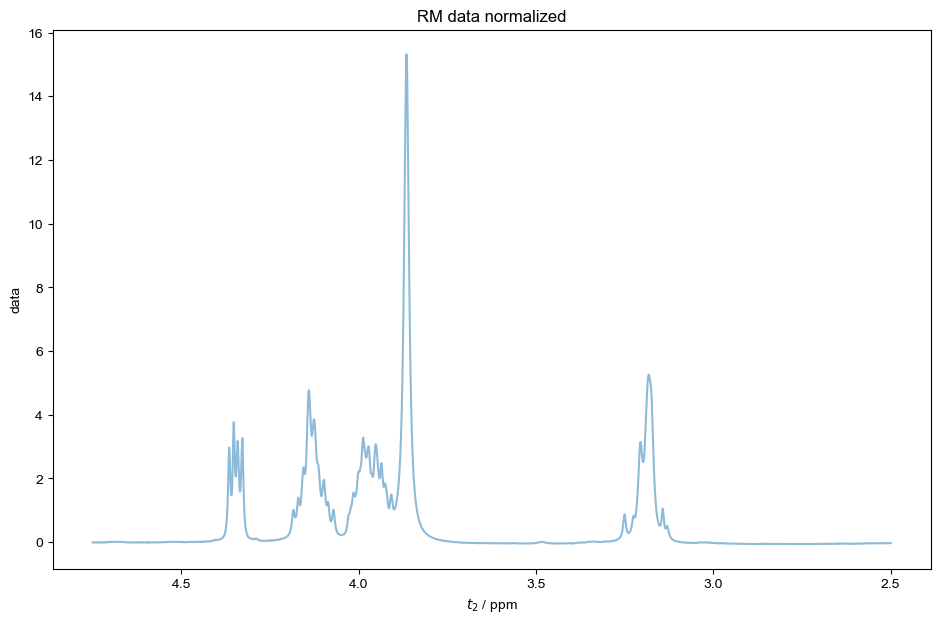

In [39]:
before_cross = load_pdata_as_nddata("w1.zip", (1,1), "NMR_data_RS")
before_cross = before_cross.interp("t2",baseline_for_int["t2"].copy())
aot_int = before_cross["t2":aot_range].integrate("t2")
before_cross /= aot_int.item()
fl.next("RM data normalized")
fl.plot(before_cross)

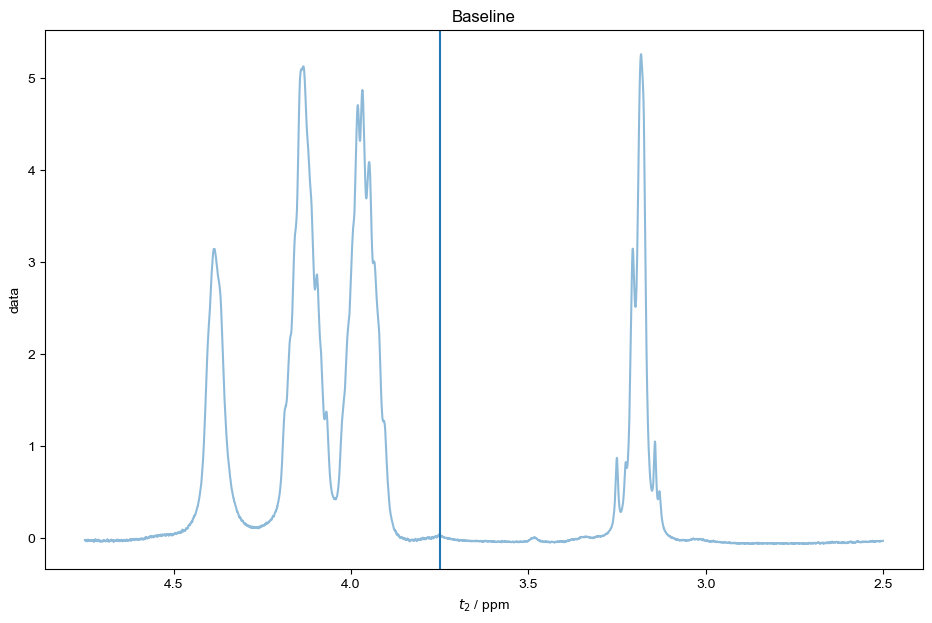

In [40]:
crossover = 3.75 # where the water peak joins the AOT peak
baseline_for_int["t2":(0,crossover)] = before_cross["t2":(0,crossover)]
fl.next("Baseline")
fl.plot(baseline_for_int)
plt.axvline(crossover)

# Now open the RM data and subtract the baseline

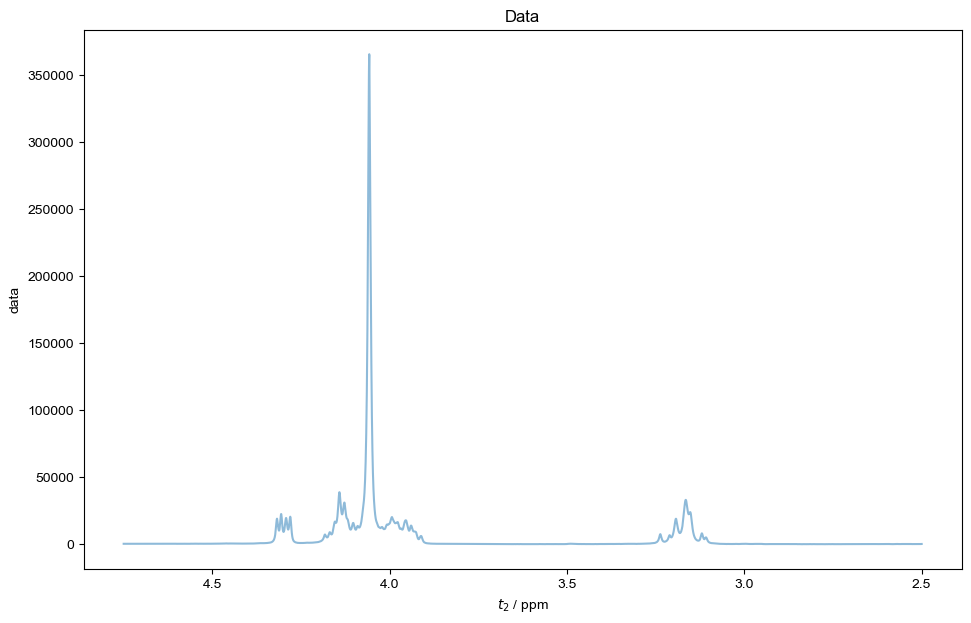

In [59]:
d = load_pdata_as_nddata("w3.zip",(1,1),"NMR_data_RS")
d = d.interp("t2", baseline_for_int["t2"].copy())
fl.next("Data")
fl.plot(d)

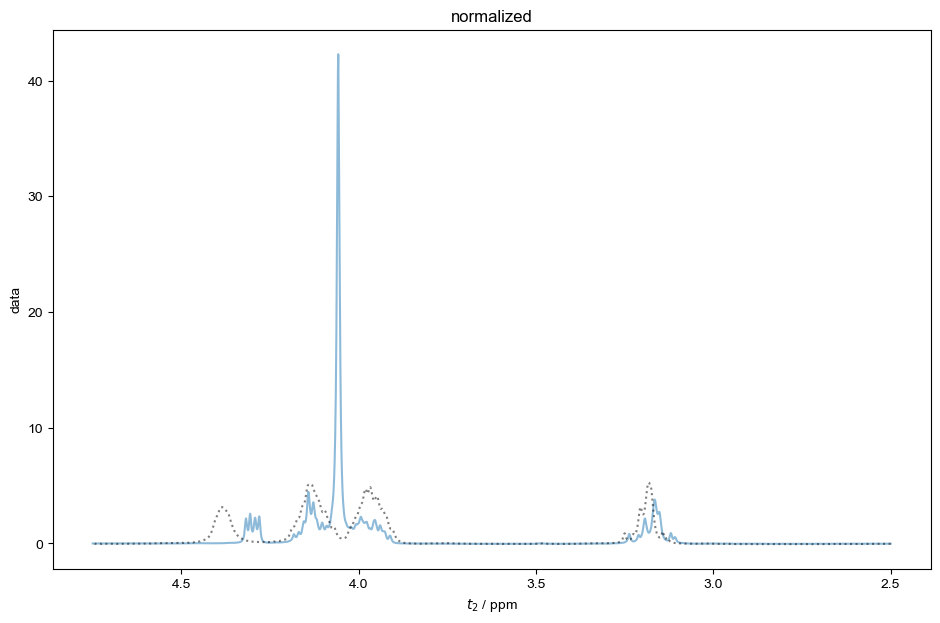

In [60]:
# Normalize
d /= d["t2":aot_range].integrate("t2").item()
fl.next("normalized")
fl.plot(d)
fl.plot(baseline_for_int, alpha = 0.5, color = "k", ls = ":")

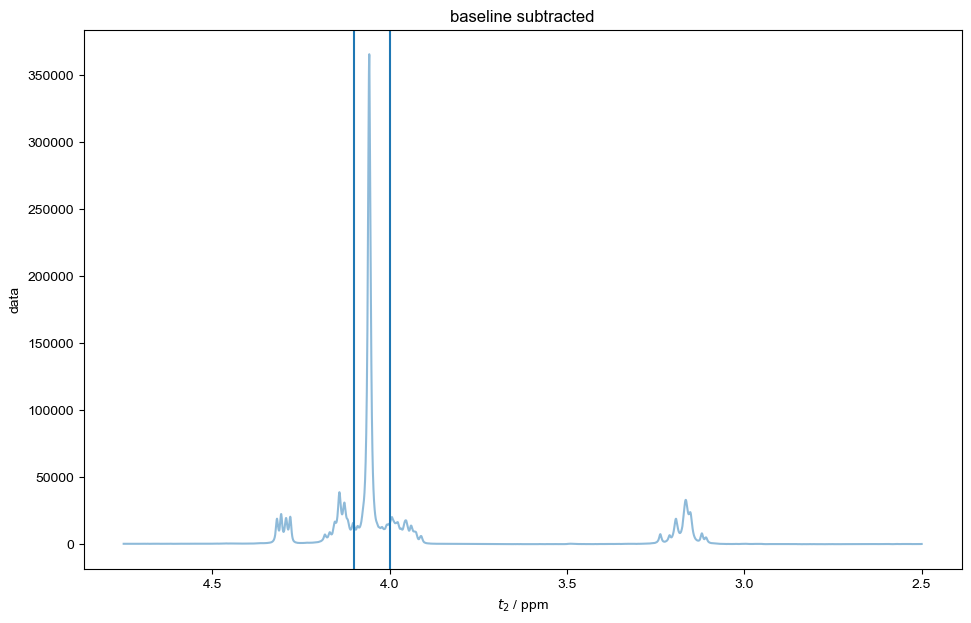

In [57]:
w0_int_range = (4.0,4.1)
thissub = (d - baseline_for_int)#["t2":w0_int_range]
fl.next("baseline subtracted")
fl.plot(thissub)
plt.axvline(w0_int_range[0])
plt.axvline(w0_int_range[1])

# Calculate integral

In [58]:
thisint = thissub.integrate("t2").item() * 6 # b/c 2 protons in water peak vs AOT peak = 1 proton
print("water loading is:",thisint)

water loading is: (59020.6910370508+0j)
